In [2]:

import os
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile, UnidentifiedImageError

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers




2026-10-25 18:43:48.229294: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792953828.250966    1415 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792953828.257564    1415 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792953828.275173    1415 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792953828.275190    1415 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792953828.275193    1415 computation_placer.cc:177] computation placer alr

In [3]:
# %pip install numpy pandas matplotlib seaborn scikit-learn tensorflow pillow
# %pip install kagglehub

In [4]:

from pathlib import Path

import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)
DATASET_DIR = Path(path)/"chest_xray"

if DATASET_DIR.exists():
    print("Dataset folder found!")
else:
    print("Error: Dataset folder not found.")
    print("Please check the folder path.")

images = ["test","train", "val"]
images_directories = []
for images_name in images : 
    images_dir = DATASET_DIR / images_name
    if images_dir.is_dir():
        print(f"{images_name} folder found!")
        images_directories.append(images_dir)   
    else:
        print(f"Error: {images_name} folder not found!")


CLASSES = ["NORMAL", "PNEUMONIA"]


for img_dic in images_directories:
    for class_name in CLASSES:
        class_dir = img_dic / class_name
        if class_dir.is_dir():
            print(f"{class_name} folder found!")
        else:
            print(f"Error: {class_name} folder not found!")

print("\nDataset location:", DATASET_DIR.resolve())
print("Classes:", CLASSES)
print(images_directories)


100%|██████████| 2.29G/2.29G [01:00<00:00, 40.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2
Dataset folder found!
test folder found!
train folder found!
val folder found!
NORMAL folder found!
PNEUMONIA folder found!
NORMAL folder found!
PNEUMONIA folder found!
NORMAL folder found!
PNEUMONIA folder found!

Dataset location: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray
Classes: ['NORMAL', 'PNEUMONIA']
[PosixPath('/root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/test'), PosixPath('/root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/train'), PosixPath('/root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/val')]


In [5]:


for images_dir in images_directories:
    print(f"\n{images_dir.name.upper()} DATASET")

    for class_name in CLASSES:
        class_dir = images_dir / class_name

        image_files = [
            file for file in class_dir.iterdir()
            if file.is_file()
            and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        print(f"{class_name}: {len(image_files)} images")



TEST DATASET
NORMAL: 234 images
PNEUMONIA: 390 images

TRAIN DATASET
NORMAL: 1341 images
PNEUMONIA: 3875 images

VAL DATASET
NORMAL: 8 images
PNEUMONIA: 8 images


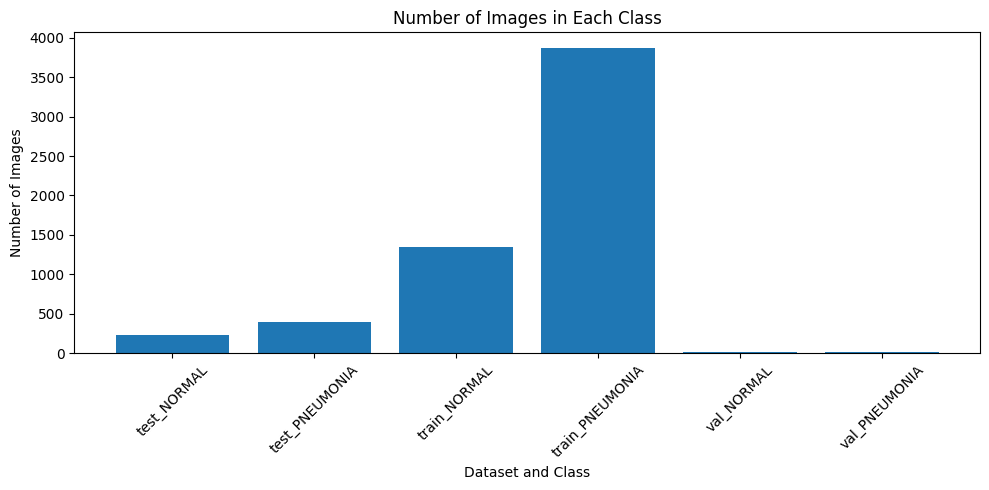

In [6]:

import matplotlib.pyplot as plt

class_counts = {}

for images_dir in images_directories:
    for class_name in CLASSES:

        class_dir = images_dir / class_name

        image_files = [
            file for file in class_dir.iterdir()
            if file.is_file()
            and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        class_counts[f"{images_dir.name}_{class_name}"] = len(image_files)

plt.figure(figsize=(10, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("Number of Images in Each Class")
plt.xlabel("Dataset and Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


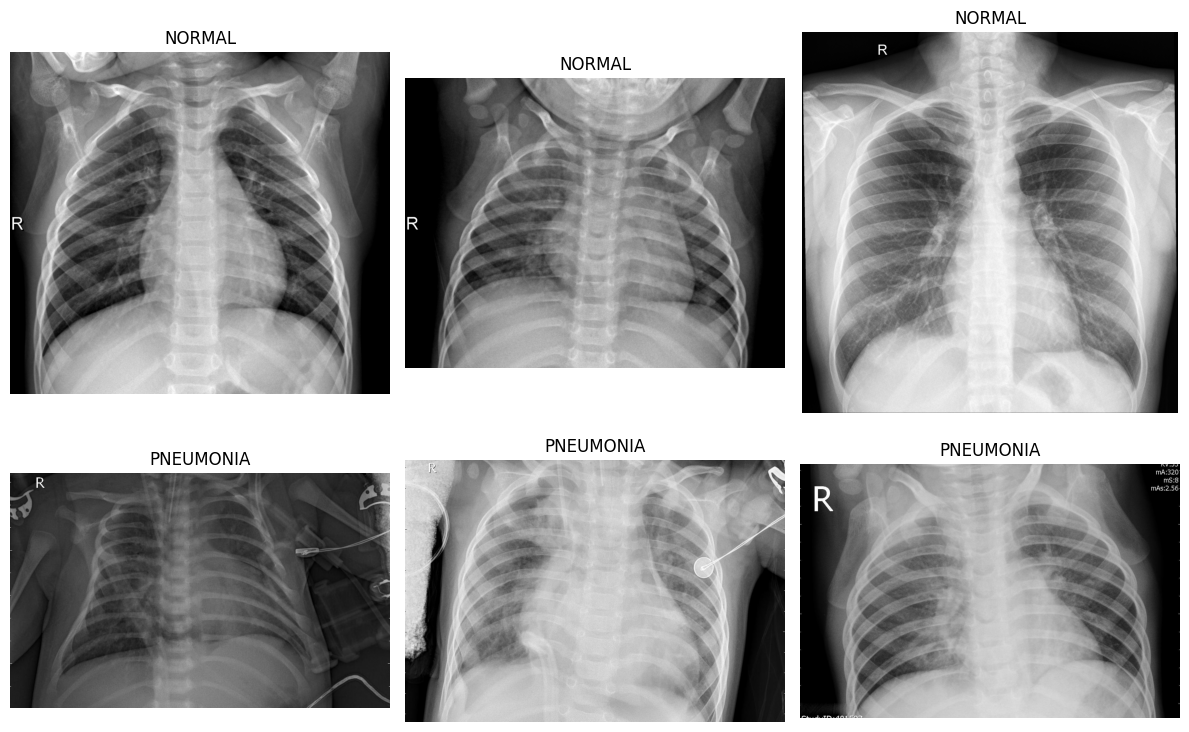

In [7]:

from PIL import Image
import random
import matplotlib.pyplot as plt

train_folder = DATASET_DIR / "train"

plt.figure(figsize=(12, 8))

for class_name in CLASSES:

    class_folder = train_folder / class_name

    image_files = list(class_folder.glob("*.jpeg"))
    image_files += list(class_folder.glob("*.jpg"))
    image_files += list(class_folder.glob("*.png"))

    samples = random.sample(image_files, min(3, len(image_files)))

    for image_path in samples:

        image = Image.open(image_path)

        plt.subplot(2, 3, len(plt.gcf().axes) + 1)
        plt.imshow(image, cmap="gray")
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()


Original size: (2090, 1858)
Original format: L
New size: (180, 180)
New format: RGB


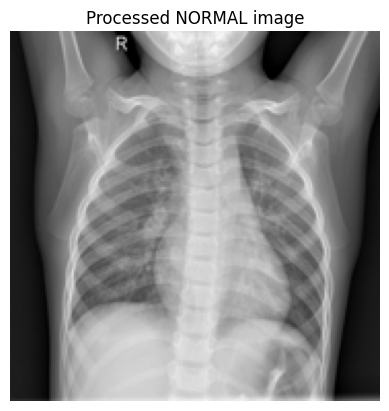

In [8]:

from PIL import Image
import matplotlib.pyplot as plt

normal_folder = DATASET_DIR / "train" / "NORMAL"

image_files = list(normal_folder.glob("*.jpeg"))
image_files += list(normal_folder.glob("*.jpg"))
image_files += list(normal_folder.glob("*.png"))

image_path = image_files[0]

image = Image.open(image_path)

print("Original size:", image.size)
print("Original format:", image.mode)

image = image.resize((180, 180))

image = image.convert("RGB")

print("New size:", image.size)
print("New format:", image.mode)

plt.imshow(image)
plt.title("Processed NORMAL image")
plt.axis("off")
plt.show()


In [9]:

import numpy as np
from PIL import Image

def load_split(split_name):
    folder = DATASET_DIR / split_name
    X = []
    y = []

    for class_name in CLASSES:
        class_folder = folder / class_name

        image_files = list(class_folder.glob("*.jpeg"))
        image_files += list(class_folder.glob("*.jpg"))
        image_files += list(class_folder.glob("*.png"))

        if class_name == "NORMAL":
            label = 0
        else:
            label = 1

        for image_path in image_files:
            image = Image.open(image_path)
            image = image.convert("RGB")
            image = image.resize((180, 180))
            image_array = np.array(image)

            X.append(image_array)    
            y.append(label)

    
    return np.array(X), np.array(y)
    




X_all, y_all = load_split("train")
# X_val,   y_val   = load_split("val")
X_test,  y_test  = load_split("test")

X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all,
    test_size=0.2,       
    stratify=y_all,      
    random_state=42
)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)



Train: (4172, 180, 180, 3) (4172,)
Val:   (1044, 180, 180, 3) (1044,)
Test:  (624, 180, 180, 3) (624,)


In [10]:
X_train = X_train.astype("float32") / 255.0
X_val   = X_val.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

print(X_train.min(), X_train.max())     # 0.0 and 1.0

0.0 1.0


In [11]:
print("Train :", X_train.shape, y_train.shape)
print("Val   :", X_val.shape, y_val.shape)
print("Test  :", X_test.shape, y_test.shape)

print("Pixel minimum :", X_train.min())
print("Pixel maximum :", X_train.max())

print("Labels :", np.unique(y_train))

Train : (4172, 180, 180, 3) (4172,)
Val   : (1044, 180, 180, 3) (1044,)
Test  : (624, 180, 180, 3) (624,)
Pixel minimum : 0.0
Pixel maximum : 1.0
Labels : [0 1]


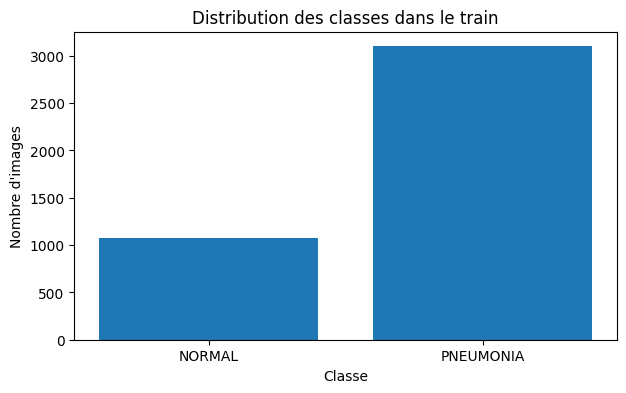

In [12]:
import matplotlib.pyplot as plt

class_names = ["NORMAL", "PNEUMONIA"]

counts = [
    np.sum(y_train == 0),
    np.sum(y_train == 1)
]

plt.figure(figsize=(7, 4))
plt.bar(class_names, counts)
plt.title("Distribution des classes dans le train")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.show()

In [13]:
print("TensorFlow:", tf.__version__)

TensorFlow: 2.19.0


In [14]:
from tensorflow.keras import layers, models
model = models.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.RandomRotation(0.03),
    layers.RandomZoom(0.1),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

I0000 00:00:1792954000.772202    1415 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22151 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4090, pci bus id: 0000:01:00.0, compute capability: 8.9


In [15]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 180, 180, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
EPOCHS = 20
BATCH_SIZE = 32

In [18]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

Epoch 1/20


I0000 00:00:1792954007.020415    1614 cuda_dnn.cc:529] Loaded cuDNN version 90300


131/131 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.7683 - loss: 0.5000 - precision: 0.7996 - recall: 0.9288 - val_accuracy: 0.9387 - val_loss: 0.1446 - val_precision: 0.9635 - val_recall: 0.9536
Epoch 2/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9123 - loss: 0.2396 - precision: 0.9333 - recall: 0.9517 - val_accuracy: 0.8515 - val_loss: 0.3388 - val_precision: 1.0000 - val_recall: 0.8003
Epoch 3/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9177 - loss: 0.2271 - precision: 0.9436 - recall: 0.9464 - val_accuracy: 0.9540 - val_loss: 0.1263 - val_precision: 0.9655 - val_recall: 0.9729
Epoch 4/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9337 - loss: 0.1685 - precision: 0.9506 - recall: 0.9609 - val_accuracy: 0.9425 - val_loss: 0.1329 - val_precision: 0.9904 - val_recall: 0.9317
Epoch 5/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9470 - loss: 0.1509 - precision: 0.9567 - recall: 0.9719 - val_accuracy: 0.9684 - val_loss: 0.0789 -

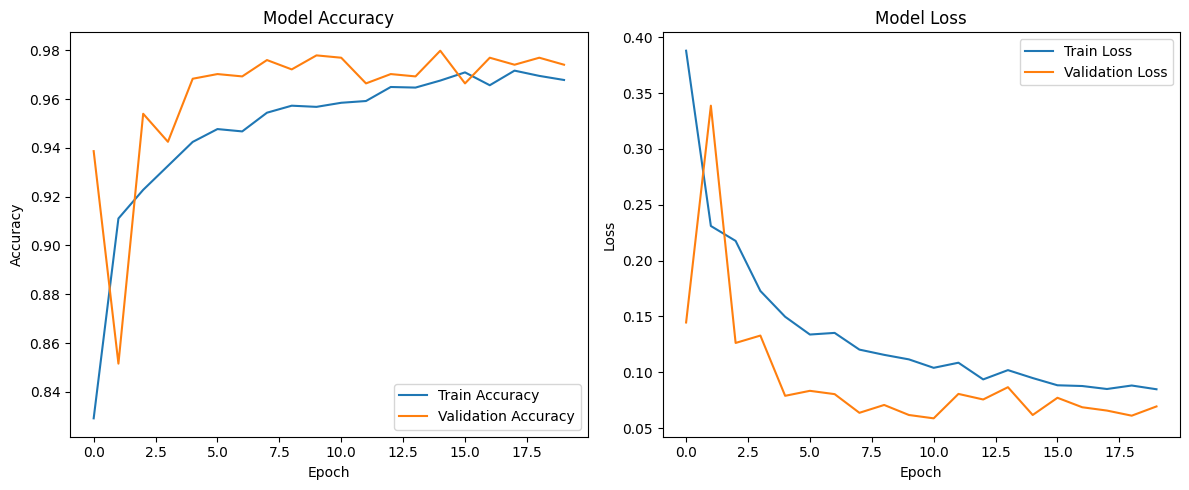

In [19]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [20]:
best_accuracy = max(history.history["val_accuracy"])
best_loss = min(history.history["val_loss"])

print(f"Best validation accuracy: {best_accuracy:.4f}")
print(f"Best validation loss: {best_loss:.4f}")

Best validation accuracy: 0.9799
Best validation loss: 0.0587


In [21]:
import tensorflow as tf
import time

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

In [22]:
start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=BATCH_SIZE,
    callbacks=callbacks
)

training_time = time.time() - start_time

print(f"Training time: {training_time:.2f} seconds")
print(f"Epochs completed: {len(history.history['loss'])}")

Epoch 1/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9660 - loss: 0.0855 - precision: 0.9734 - recall: 0.9808 - val_accuracy: 0.9837 - val_loss: 0.0493 - val_precision: 0.9897 - val_recall: 0.9884 - learning_rate: 0.0010
Epoch 2/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9733 - loss: 0.0741 - precision: 0.9810 - recall: 0.9828 - val_accuracy: 0.9770 - val_loss: 0.0682 - val_precision: 0.9987 - val_recall: 0.9704 - learning_rate: 0.0010
Epoch 3/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9754 - loss: 0.0707 - precision: 0.9844 - recall: 0.9828 - val_accuracy: 0.9780 - val_loss: 0.0595 - val_precision: 0.9947 - val_recall: 0.9755 - learning_rate: 0.0010
Epoch 4/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9835 - loss: 0.0539 - precision: 0.9880 - recall: 0.9899 - val_accuracy: 0.9837 - val_loss: 0.0484 - val_precision: 0.9948 - val_recall: 0.9832 - learning_rate: 5.0000e-04
Epoch 5/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - a

In [23]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_prob = model.predict(X_test).ravel()

y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Accuracy:  0.7564
Precision: 0.7212
Recall:    0.9949
F1-score:  0.8362
ROC-AUC:   0.9472


In [24]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


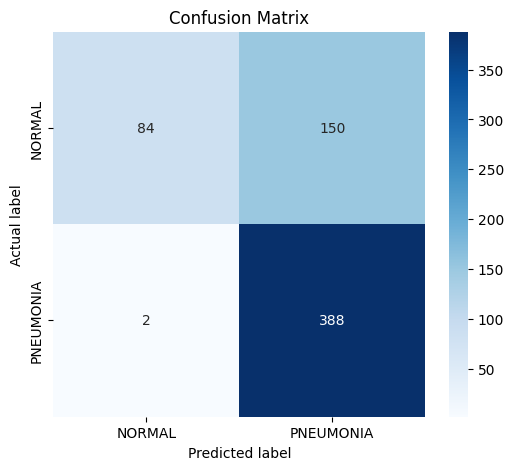

              precision    recall  f1-score   support

      NORMAL       0.98      0.36      0.53       234
   PNEUMONIA       0.72      0.99      0.84       390

    accuracy                           0.76       624
   macro avg       0.85      0.68      0.68       624
weighted avg       0.82      0.76      0.72       624



In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

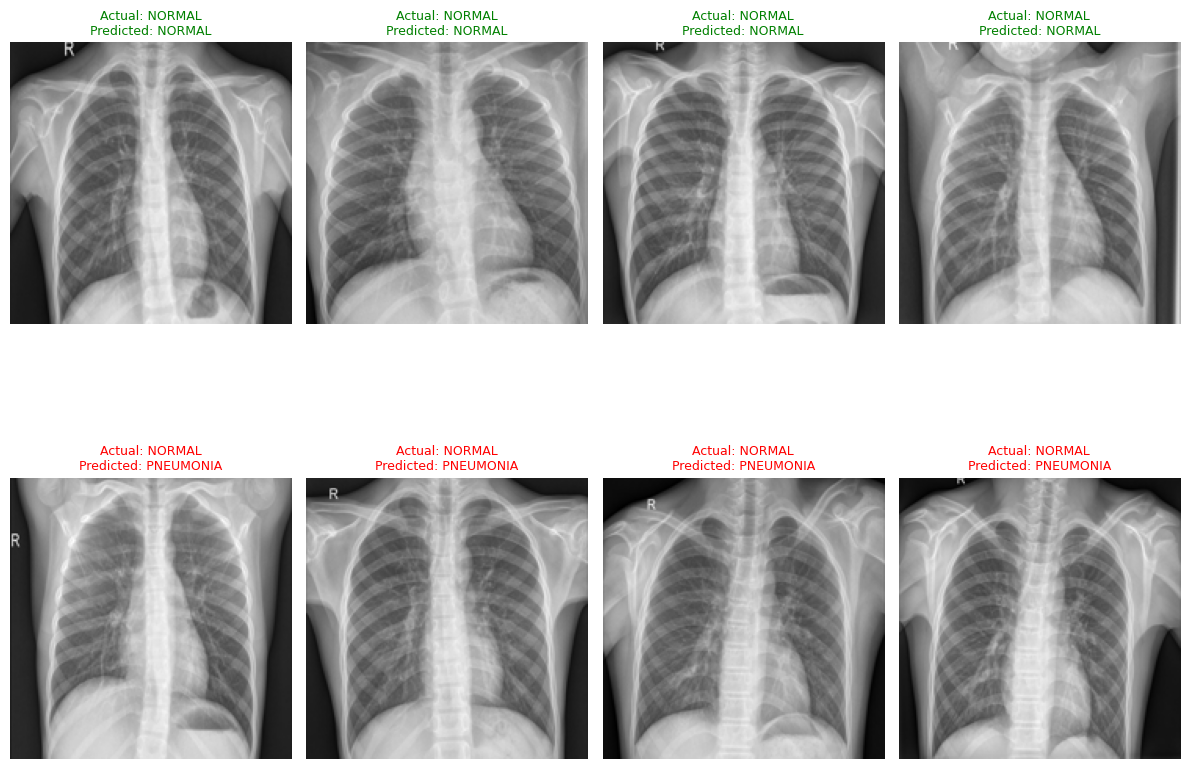

In [26]:
import matplotlib.pyplot as plt
import numpy as np

correct_indices = np.where(y_pred == y_test)[0]
incorrect_indices = np.where(y_pred != y_test)[0]

selected_correct = correct_indices[:4]
selected_incorrect = incorrect_indices[:4]

selected_indices = np.concatenate([
    selected_correct,
    selected_incorrect
])

plt.figure(figsize=(12, 10))

for i, idx in enumerate(selected_indices):
    plt.subplot(2, 4, i + 1)

    plt.imshow(X_test[idx])

    actual_label = "PNEUMONIA" if y_test[idx] == 1 else "NORMAL"
    predicted_label = "PNEUMONIA" if y_pred[idx] == 1 else "NORMAL"

    color = "green" if y_pred[idx] == y_test[idx] else "red"

    plt.title(
        f"Actual: {actual_label}\nPredicted: {predicted_label}",
        color=color,
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import accuracy_score

train_pred = (model.predict(X_train, verbose=0).ravel() >= 0.5).astype(int)
val_pred = (model.predict(X_val, verbose=0).ravel() >= 0.5).astype(int)
test_pred = (model.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)

train_accuracy = accuracy_score(y_train, train_pred)
val_accuracy = accuracy_score(y_val, val_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print(f"Training Accuracy:   {train_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Test Accuracy:       {test_accuracy:.4f}")

Training Accuracy:   0.9923
Validation Accuracy: 0.9837
Test Accuracy:       0.7564


In [28]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

import numpy as np
import matplotlib.pyplot as plt

In [29]:
print("Shape:", X_train.shape)
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Shape: (4172, 180, 180, 3)
Minimum: 0.0
Maximum: 1.0


In [30]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Vérifier si les images sont déjà normalisées entre 0 et 1
images_normalized = X_train.max() <= 1.0

# def prepare_batch(images, labels):
#     # Revenir à l'échelle 0-255 si nécessaire
#     if images_normalized:
#         images = images * 255.0

#     # Redimensionner les images
#     images = tf.image.resize(images, IMG_SIZE)

#     # Appliquer le prétraitement MobileNetV2
#     images = preprocess_input(images)

#     return images, labels

# def create_dataset(images, labels, training=False):
#     dataset = tf.data.Dataset.from_tensor_slices((images, labels))

#     if training:
#         dataset = dataset.shuffle(
#             buffer_size=min(len(images), 1000),
#             reshuffle_each_iteration=True
#         )

#     dataset = dataset.batch(BATCH_SIZE)
#     dataset = dataset.map(
#         prepare_batch,
#         num_parallel_calls=tf.data.AUTOTUNE
#     )
#     return dataset.prefetch(tf.data.AUTOTUNE)

# train_ds_mobilenet = create_dataset(
#     X_train, y_train, training=True
# )

# val_ds_mobilenet = create_dataset(
#     X_val, y_val
# )

# test_ds_mobilenet = create_dataset(
#     X_test, y_test
# )

X_images =[X_train, X_val, X_test]
X_processed = []
for images in X_images:
    if images_normalized:
        images = images * 255.0
    images = tf.image.resize(images, IMG_SIZE)
    images = preprocess_input(images)
    X_processed.append(images.numpy())

X_train_mobilenet, X_val_mobilenet, X_test_mobilenet = X_processed


In [31]:
# for images, labels in train_ds_mobilenet.take(1):
#     print("Image batch:", images.shape)
#     print("Labels batch:", labels.shape)
#     print("Minimum des pixels:", tf.reduce_min(images).numpy())
#     print("Maximum des pixels:", tf.reduce_max(images).numpy())

for x, y in zip(X_train_mobilenet, y_train):
    print("Image shape:", x.shape)
    print("Label:", y)
    print("Minimum des pixels:", tf.reduce_min(x).numpy())
    print("Maximum des pixels:", tf.reduce_max(x).numpy())
    break

Image shape: (224, 224, 3)
Label: 0
Minimum des pixels: -1.0
Maximum des pixels: 0.9827032


In [32]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [33]:
base_model.trainable = False

In [34]:
# Entrée : image RGB de 224 × 224
inputs = keras.Input(shape=(224, 224, 3))

# Extraire les caractéristiques avec MobileNetV2
x = base_model(inputs, training=False)

# Réduire les dimensions des caractéristiques
x = layers.GlobalAveragePooling2D()(x)

# Réduire le risque de surapprentissage
x = layers.Dropout(0.3)(x)

# Prédiction binaire
outputs = layers.Dense(1, activation="sigmoid")(x)

# Créer le modèle complet
model_mobilenet = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="ChestScan_MobileNetV2"
)

In [35]:
model_mobilenet.summary()

Model: "ChestScan_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [36]:
trainable_params = sum(
    np.prod(v.shape)
    for v in model_mobilenet.trainable_weights
)

non_trainable_params = sum(
    np.prod(v.shape)
    for v in model_mobilenet.non_trainable_weights
)

print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)

Trainable parameters: 1281
Non-trainable parameters: 2257984


In [37]:
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [38]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7
)

In [39]:
import time

start_time = time.time()

# history_mobilenet = model_mobilenet.fit(
#     train_ds_mobilenet,
#     validation_data=val_ds_mobilenet,
#     epochs=15,
#     callbacks=[early_stopping, reduce_lr]
# )

history_mobilenet = model_mobilenet.fit(
    X_train_mobilenet, y_train,
    validation_data= (X_val_mobilenet, y_val),
    batch_size= BATCH_SIZE,
    epochs= EPOCHS,
    callbacks=[early_stopping, reduce_lr]
)

training_time = time.time() - start_time

print(f"Training time: {training_time:.2f} seconds")




Epoch 1/20


I0000 00:00:1792954101.843657    1610 service.cc:152] XLA service 0x7fd39c001340 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792954101.843707    1610 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 4090, Compute Capability 8.9
2026-10-25 18:48:21.987222: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


 16/131 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6025 - loss: 0.6869

I0000 00:00:1792954105.510991    1610 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


131/131 ━━━━━━━━━━━━━━━━━━━━ 18s 86ms/step - accuracy: 0.7748 - loss: 0.4564 - val_accuracy: 0.9406 - val_loss: 0.1808 - learning_rate: 0.0010
Epoch 2/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9368 - loss: 0.1727 - val_accuracy: 0.9579 - val_loss: 0.1350 - learning_rate: 0.0010
Epoch 3/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9509 - loss: 0.1424 - val_accuracy: 0.9646 - val_loss: 0.1149 - learning_rate: 0.0010
Epoch 4/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9539 - loss: 0.1212 - val_accuracy: 0.9646 - val_loss: 0.1047 - learning_rate: 0.0010
Epoch 5/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9586 - loss: 0.1123 - val_accuracy: 0.9646 - val_loss: 0.0970 - learning_rate: 0.0010
Epoch 6/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9673 - loss: 0.0901 - val_accuracy: 0.9646 - val_loss: 0.0934 - learning_rate: 0.0010
Epoch 7/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9619 - loss: 0.1039 - val

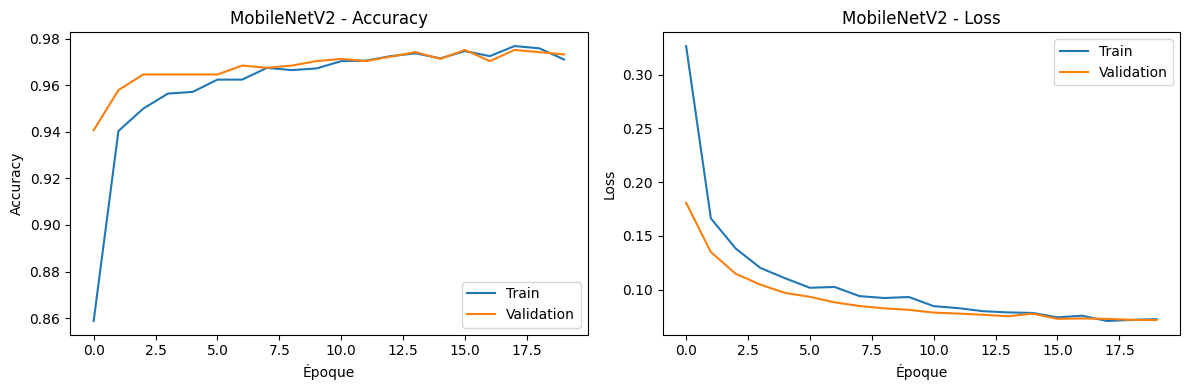

In [40]:
plt.figure(figsize=(12, 4))

# Courbes d'accuracy
plt.subplot(1, 2, 1)
plt.plot(history_mobilenet.history["accuracy"], label="Train")
plt.plot(history_mobilenet.history["val_accuracy"], label="Validation")
plt.title("MobileNetV2 - Accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()

# Courbes de loss
plt.subplot(1, 2, 2)
plt.plot(history_mobilenet.history["loss"], label="Train")
plt.plot(history_mobilenet.history["val_loss"], label="Validation")
plt.title("MobileNetV2 - Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Probabilités prédites par MobileNetV2
# y_prob_mobilenet = model_mobilenet.predict(
#     test_ds_mobilenet
# ).ravel()
y_prob_mobilenet = model_mobilenet.predict(
    X_test_mobilenet
).ravel()

# Transformer les probabilités en classes 0 ou 1
y_pred_mobilenet = (
    y_prob_mobilenet >= 0.5
).astype(int)

# Labels réels
y_true = np.asarray(y_test).ravel().astype(int)

# Calcul des métriques
print("Accuracy:", accuracy_score(y_true, y_pred_mobilenet))
print("Precision:", precision_score(y_true, y_pred_mobilenet, zero_division=0))
print("Recall:", recall_score(y_true, y_pred_mobilenet, zero_division=0))
print("F1-score:", f1_score(y_true, y_pred_mobilenet, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_true, y_prob_mobilenet))

print("\nClassification report:")
print(classification_report(y_true, y_pred_mobilenet, zero_division=0))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred_mobilenet))

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 179ms/step
Accuracy: 0.8173076923076923
Precision: 0.776
Recall: 0.9948717948717949
F1-score: 0.8719101123595505
ROC-AUC: 0.9575717729563884

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.52      0.68       234
           1       0.78      0.99      0.87       390

    accuracy                           0.82       624
   macro avg       0.88      0.76      0.78       624
weighted avg       0.85      0.82      0.80       624


Confusion matrix:
[[122 112]
 [  2 388]]


In [42]:
import tensorflow as tf
from tensorflow.keras import layers

# 1. Create a separate copy of the Transfer Learning model
model_mobilenet_finetuned = tf.keras.models.clone_model(
    model_mobilenet
)

model_mobilenet_finetuned.set_weights(
    model_mobilenet.get_weights()
)

# 2. Get the MobileNetV2 base model from the copied model
base_model_finetuned = model_mobilenet_finetuned.get_layer(
    "mobilenetv2_1.00_224"
)

# 3. Unfreeze the base model
base_model_finetuned.trainable = True

# 4. Freeze all but the last 20 layers
fine_tune_at = len(base_model_finetuned.layers) - 20

for layer in base_model_finetuned.layers[:fine_tune_at]:
    layer.trainable = False

# 5. Keep BatchNormalization layers frozen
for layer in base_model_finetuned.layers[fine_tune_at:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# 6. Recompile with a low learning rate
model_mobilenet_finetuned.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [43]:
# Arrêter si la validation ne s'améliore plus
early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Réduire encore le learning rate si nécessaire
reduce_lr_ft = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7
)

# Continuer l'entraînement avec les dernières couches débloquées
# history_finetune = model_mobilenet.fit(
#     train_ds_mobilenet,
#     validation_data=val_ds_mobilenet,
#     epochs=10,
#     callbacks=[early_stopping_ft, reduce_lr_ft]
# )
history_finetune = model_mobilenet_finetuned.fit(
    X_train_mobilenet,y_train,
    validation_data=(X_val_mobilenet, y_val),
    epochs=10,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping_ft, reduce_lr_ft]
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 18s 84ms/step - accuracy: 0.9748 - loss: 0.0676 - val_accuracy: 0.9751 - val_loss: 0.0638 - learning_rate: 1.0000e-05
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9828 - loss: 0.0540 - val_accuracy: 0.9761 - val_loss: 0.0610 - learning_rate: 1.0000e-05
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9861 - loss: 0.0421 - val_accuracy: 0.9751 - val_loss: 0.0617 - learning_rate: 1.0000e-05
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9863 - loss: 0.0431 - val_accuracy: 0.9780 - val_loss: 0.0616 - learning_rate: 1.0000e-05
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9876 - loss: 0.0326 - val_accuracy: 0.9789 - val_loss: 0.0571 - learning_rate: 2.0000e-06
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9871 - loss: 0.0329 - val_accuracy: 0.9780 - val_loss: 0.0561 - learning_rate: 2.0000e-06
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - ac

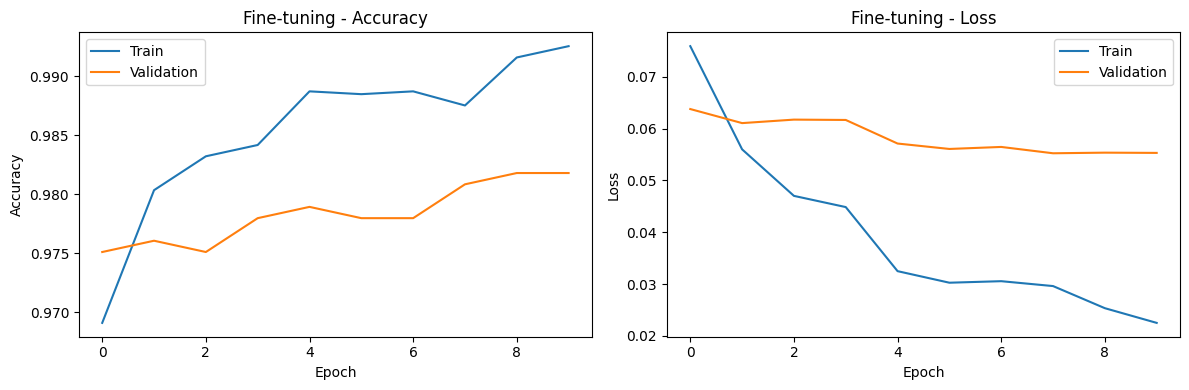

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_finetune.history["accuracy"], label="Train")
plt.plot(history_finetune.history["val_accuracy"], label="Validation")
plt.title("Fine-tuning - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_finetune.history["loss"], label="Train")
plt.plot(history_finetune.history["val_loss"], label="Validation")
plt.title("Fine-tuning - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import numpy as np

# Véritables labels
y_true = np.asarray(y_test).ravel().astype(int)

# Probabilités prédites par le modèle fine-tuné
# y_prob_after = model_mobilenet.predict(
#     test_ds_mobilenet, verbose=0
# ).ravel()
y_prob_after = model_mobilenet_finetuned.predict(
    X_test_mobilenet, verbose=0
).ravel()

# Transformer les probabilités en classes : 0 ou 1
y_pred_after = (y_prob_after >= 0.5).astype(int)

# Calculer les métriques
print("Accuracy :", accuracy_score(y_true, y_pred_after))
print("Precision:", precision_score(y_true, y_pred_after, zero_division=0))
print("Recall   :", recall_score(y_true, y_pred_after, zero_division=0))
print("F1-score :", f1_score(y_true, y_pred_after, zero_division=0))

print("\nRapport de classification :")
print(classification_report(
    y_true,
    y_pred_after,
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

Accuracy : 0.8253205128205128
Precision: 0.781563126252505
Recall   : 1.0
F1-score : 0.8773903262092239

Rapport de classification :
              precision    recall  f1-score   support

      NORMAL       1.00      0.53      0.70       234
   PNEUMONIA       0.78      1.00      0.88       390

    accuracy                           0.83       624
   macro avg       0.89      0.77      0.79       624
weighted avg       0.86      0.83      0.81       624



In [46]:
print("AVANT le fine-tuning")
print("Accuracy :", accuracy_score(y_true, y_pred_mobilenet))
print("Precision:", precision_score(
    y_true, y_pred_mobilenet, zero_division=0
))
print("Recall   :", recall_score(
    y_true, y_pred_mobilenet, zero_division=0
))
print("F1-score :", f1_score(
    y_true, y_pred_mobilenet, zero_division=0
))

print("\nAPRÈS le fine-tuning")
print("Accuracy :", accuracy_score(y_true, y_pred_after))
print("Precision:", precision_score(
    y_true, y_pred_after, zero_division=0
))
print("Recall   :", recall_score(
    y_true, y_pred_after, zero_division=0
))
print("F1-score :", f1_score(
    y_true, y_pred_after, zero_division=0
))

AVANT le fine-tuning
Accuracy : 0.8173076923076923
Precision: 0.776
Recall   : 0.9948717948717949
F1-score : 0.8719101123595505

APRÈS le fine-tuning
Accuracy : 0.8253205128205128
Precision: 0.781563126252505
Recall   : 1.0
F1-score : 0.8773903262092239


In [47]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    classification_report,
    confusion_matrix
)

def evaluate_model(name, model, X_test_model, y_test):
    # Predict probabilities
    y_prob = model.predict(X_test_model, verbose=0).ravel()

    # Convert probabilities into class predictions
    y_pred = (y_prob >= 0.5).astype(int)

    # Calculate metrics
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Loss": log_loss(
            y_test,
            np.clip(y_prob, 1e-7, 1 - 1e-7)
        )
    }

    print(f"\n--- {name} ---")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        zero_division=0
    ))

    return results, y_pred, y_prob

In [48]:
results = []

# CNN trained from scratch
r_cnn, pred_cnn, prob_cnn = evaluate_model(
    "CNN from Scratch",
    model,
    X_test,
    y_test
)
results.append(r_cnn)

# MobileNetV2 - Transfer Learning
r_tl, pred_tl, prob_tl = evaluate_model(
    "MobileNetV2 - Transfer Learning",
    model_mobilenet,
    X_test_mobilenet,
    y_test
)
results.append(r_tl)

# MobileNetV2 - Fine-tuning
r_ft, pred_ft, prob_ft = evaluate_model(
    "MobileNetV2 - Fine-tuning",
    model_mobilenet_finetuned,
    X_test_mobilenet,
    y_test
)
results.append(r_ft)

comparison_df = pd.DataFrame(results).set_index("Model")
display(comparison_df.round(4))


--- CNN from Scratch ---
              precision    recall  f1-score   support

      NORMAL       0.98      0.36      0.53       234
   PNEUMONIA       0.72      0.99      0.84       390

    accuracy                           0.76       624
   macro avg       0.85      0.68      0.68       624
weighted avg       0.82      0.76      0.72       624


--- MobileNetV2 - Transfer Learning ---
              precision    recall  f1-score   support

      NORMAL       0.98      0.52      0.68       234
   PNEUMONIA       0.78      0.99      0.87       390

    accuracy                           0.82       624
   macro avg       0.88      0.76      0.78       624
weighted avg       0.85      0.82      0.80       624


--- MobileNetV2 - Fine-tuning ---
              precision    recall  f1-score   support

      NORMAL       1.00      0.53      0.70       234
   PNEUMONIA       0.78      1.00      0.88       390

    accuracy                           0.83       624
   macro avg       0.89   

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Loss
Model,,,,,,
CNN from Scratch,0.7564,0.7212,0.9949,0.8362,0.9472,1.0712
MobileNetV2 - Transfer Learning,0.8173,0.7760,0.9949,0.8719,0.9576,0.5249
MobileNetV2 - Fine-tuning,0.8253,0.7816,1.0000,0.8774,0.9609,0.7468


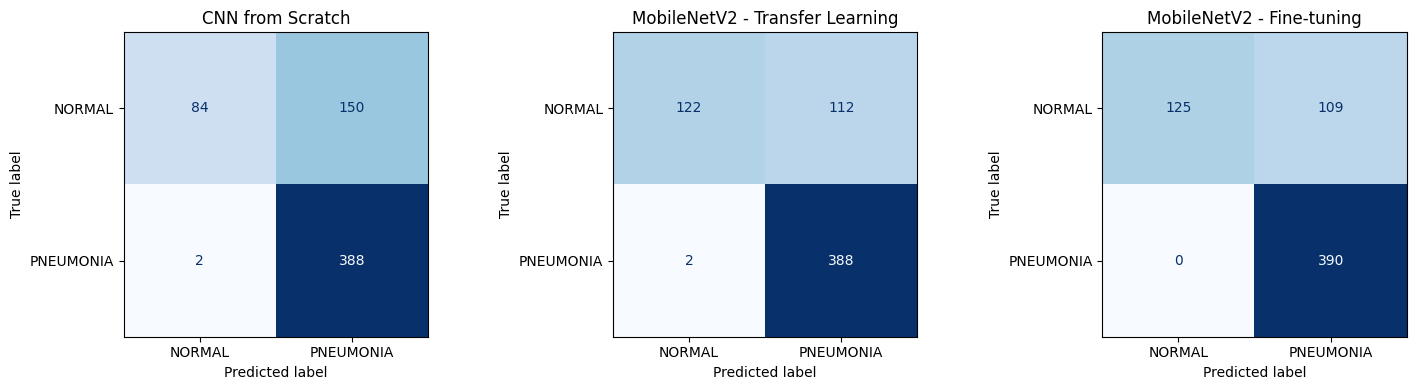

In [49]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

predictions = [
    ("CNN from Scratch", pred_cnn),
    ("MobileNetV2 - Transfer Learning", pred_tl),
    ("MobileNetV2 - Fine-tuning", pred_ft)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["NORMAL", "PNEUMONIA"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()

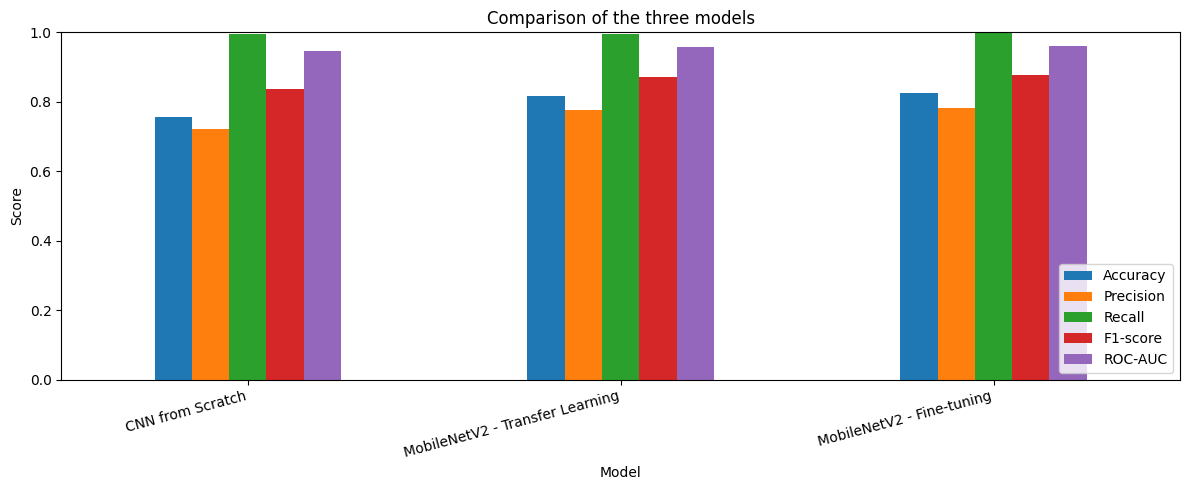

In [50]:
comparison_df[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 5))

plt.title("Comparison of the three models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [51]:

from pathlib import Path
import json

# 1. Create a folder to store the model
MODEL_DIR = Path.cwd() / "saved_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 2. Define the model file path
MODEL_PATH = MODEL_DIR / "ChestScan_MobileNetV2_Finetuned.keras"

# 3. Save the fine-tuned model
model_mobilenet_finetuned.save(MODEL_PATH)

print(f"Model saved to: {MODEL_PATH.resolve()}")

# 4. Create the model metadata
metadata = {
    "image_size": [224, 224],
    "class_names": ["NORMAL", "PNEUMONIA"],
    "positive_class": "PNEUMONIA",
    "preprocessing": (
        "tensorflow.keras.applications.mobilenet_v2.preprocess_input"
    ),
    "input_pixel_range": [0, 255],
    "preprocessed_pixel_range": [-1, 1],
    "threshold": 0.5
}

# 5. Save the metadata as JSON
METADATA_PATH = MODEL_DIR / "model_metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print(f"Metadata saved to: {METADATA_PATH.resolve()}")

# 6. Display the files and their sizes
print("\nSaved files:")
for file_path in MODEL_DIR.iterdir():
    if file_path.is_file():
        size_mb = file_path.stat().st_size / (1024 * 1024)
        print(f"{file_path.name} — {size_mb:.2f} MB")


Model saved to: /saved_models/ChestScan_MobileNetV2_Finetuned.keras
Metadata saved to: /saved_models/model_metadata.json

Saved files:
ChestScan_MobileNetV2_Finetuned.keras — 18.31 MB
model_metadata.json — 0.00 MB


In [52]:
import numpy as np
import tensorflow as tf

loaded_model = tf.keras.models.load_model(MODEL_PATH)

print("Model reloaded successfully!")

# Compare predictions before and after saving
pred_before = model_mobilenet_finetuned.predict(
    X_test_mobilenet[:5], verbose=0
)

pred_after = loaded_model.predict(
    X_test_mobilenet[:5], verbose=0
)

print(
    "Predictions preserved:",
    np.allclose(pred_before, pred_after, atol=1e-5)
)

Model reloaded successfully!
Predictions preserved: True


In [53]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import json
import tensorflow as tf

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load metadata
with open(METADATA_PATH, "r") as f:
    metadata = json.load(f)

IMG_SIZE = tuple(metadata["image_size"])
THRESHOLD = metadata["threshold"]


def predict_xray(image_path):
    # 1. Load the X-ray image
    image = Image.open(image_path).convert("RGB")

    # 2. Resize to the expected input size
    image = image.resize(IMG_SIZE)

    # 3. Convert pixels to a NumPy array
    image_array = np.array(image, dtype=np.float32)

    # 4. Apply MobileNetV2 preprocessing: [0, 255] -> [-1, 1]
    image_array = preprocess_input(image_array)

    # 5. Add the batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # 6. Predict the probability of PNEUMONIA
    pneumonia_score = float(
        loaded_model.predict(image_array, verbose=0).ravel()[0]
    )

    # 7. Determine the predicted class
    predicted_class = (
        "PNEUMONIA"
        if pneumonia_score >= THRESHOLD
        else "NORMAL"
    )

    # 8. Display the image and results
    plt.figure(figsize=(5, 5))
    plt.imshow(Image.open(image_path).convert("RGB"))
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"PNEUMONIA score: {pneumonia_score:.2%}"
    )
    plt.axis("off")
    plt.show()

    print("Predicted class:", predicted_class)
    print(f"PNEUMONIA score: {pneumonia_score:.2%}")

    return {
        "class": predicted_class,
        "pneumonia_score": pneumonia_score
    }


Testing: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/test/NORMAL/IM-0001-0001.jpeg


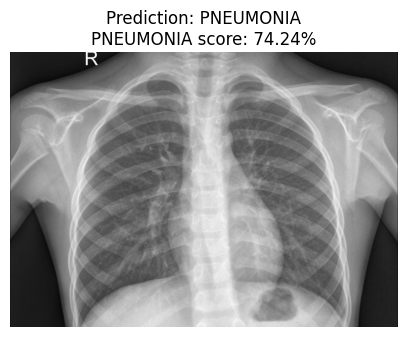

Predicted class: PNEUMONIA
PNEUMONIA score: 74.24%

Testing: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/test/NORMAL/IM-0003-0001.jpeg


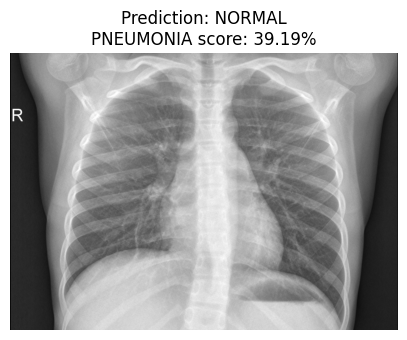

Predicted class: NORMAL
PNEUMONIA score: 39.19%

Testing: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/test/NORMAL/IM-0005-0001.jpeg


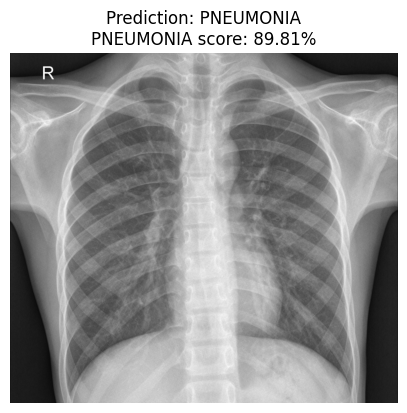

Predicted class: PNEUMONIA
PNEUMONIA score: 89.81%

Testing: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg


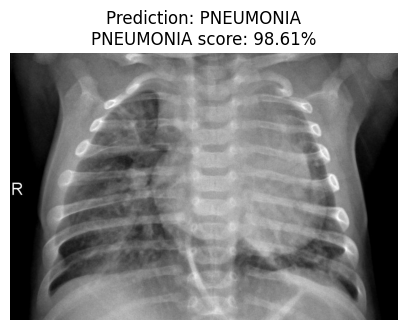

Predicted class: PNEUMONIA
PNEUMONIA score: 98.61%

Testing: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/test/PNEUMONIA/person100_bacteria_477.jpeg


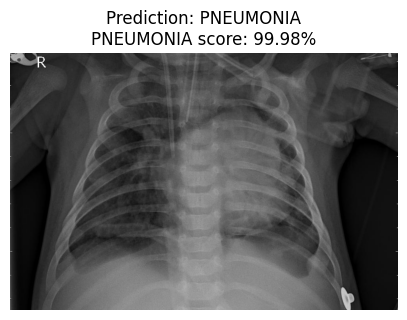

Predicted class: PNEUMONIA
PNEUMONIA score: 99.98%

Testing: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/test/PNEUMONIA/person100_bacteria_478.jpeg


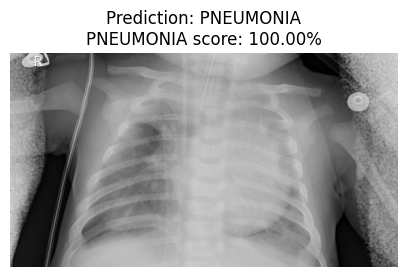

Predicted class: PNEUMONIA
PNEUMONIA score: 100.00%


In [54]:
from pathlib import Path



test_images = []

for class_name in ["NORMAL", "PNEUMONIA"]:
    class_dir = DATASET_DIR/"test"/ class_name

    images = [
        p for p in class_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    test_images.extend(images[:3])

for image_path in test_images:
    print(f"\nTesting: {image_path}")
    result = predict_xray(image_path)